# Retention, cohort survival and revenue bridges

Opening-population monthly retention and acquisition-cohort survival have different denominators. Future periods stay unavailable.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if not (root / 'scripts').exists():
    root = root.parent
assert (root / 'scripts').exists(), 'Open this notebook inside the project'
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import pandas as pd
from scripts.common import ROOT, AS_OF, read_csv
from IPython.display import display, Image


In [2]:
m = read_csv('monthly_churn_kpis')
co = read_csv('cohort_retention')
display(m[['month','is_active_start','new_customer','churn_event','is_active_end','churn_rate','retention_rate']].tail(6))
assert (m.is_active_start+m.new_customer-m.churn_event).equals(m.is_active_end)

,month,is_active_start,new_customer,churn_event,is_active_end,churn_rate,retention_rate
18,2026-03-01,6278,570,219,6629,0.029946,0.970054
19,2026-04-01,6629,566,236,6959,0.031076,0.968924
20,2026-05-01,6959,575,200,7334,0.026009,0.973991
21,2026-06-01,7334,639,239,7734,0.029997,0.970003
22,2026-07-01,7734,634,235,8133,0.026636,0.973364
23,2026-08-01,8133,665,267,8531,0.029755,0.970245


In [3]:
import numpy as np
assert np.allclose(m.start_mrr+m.new_mrr-m.churned_mrr,m.end_mrr)
assert co.loc[co.is_observed.eq(0),'retention_rate'].isna().all()
display(co.pivot(index='cohort_month',columns='cohort_age',values='retention_rate').tail(8))

cohort_age,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohort_month,,,,,,,,,,,,,,,,,,,,,
2026-01-01,0.977778,0.935185,0.890741,0.866667,0.846296,0.824074,0.805556,0.787037,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-02-01,0.971831,0.933099,0.887324,0.867958,0.852113,0.827465,0.797535,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-03-01,0.945614,0.907018,0.877193,0.849123,0.824561,0.800000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-04-01,0.946996,0.922261,0.895760,0.871025,0.849823,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-01,0.966957,0.930435,0.886957,0.857391,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-06-01,0.970266,0.940532,0.909233,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-07-01,0.954259,0.921136,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-01,0.962406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Comparable follow-up

For each age-specific KPI, keep observed cohorts only and weight by original cohort size. Month 0 is actual acquisition-month-end survival, not a forced 100%.

In [4]:
age_rates=[]
for age in [0,1,2,3,6,12,18,23]:
    g=co[co.cohort_age.eq(age)&co.is_observed.eq(1)]
    age_rates.append({'age':age,'eligible_customers':int(g.cohort_size.sum()),'retention':g.retained_customers.sum()/g.cohort_size.sum()})
display(pd.DataFrame(age_rates))

,age,eligible_customers,retention
0,0,11880,0.961195
1,1,11215,0.927508
2,2,10581,0.890842
3,3,9942,0.866828
4,6,8231,0.799538
5,12,5071,0.667521
6,18,2313,0.558582
7,23,358,0.452514


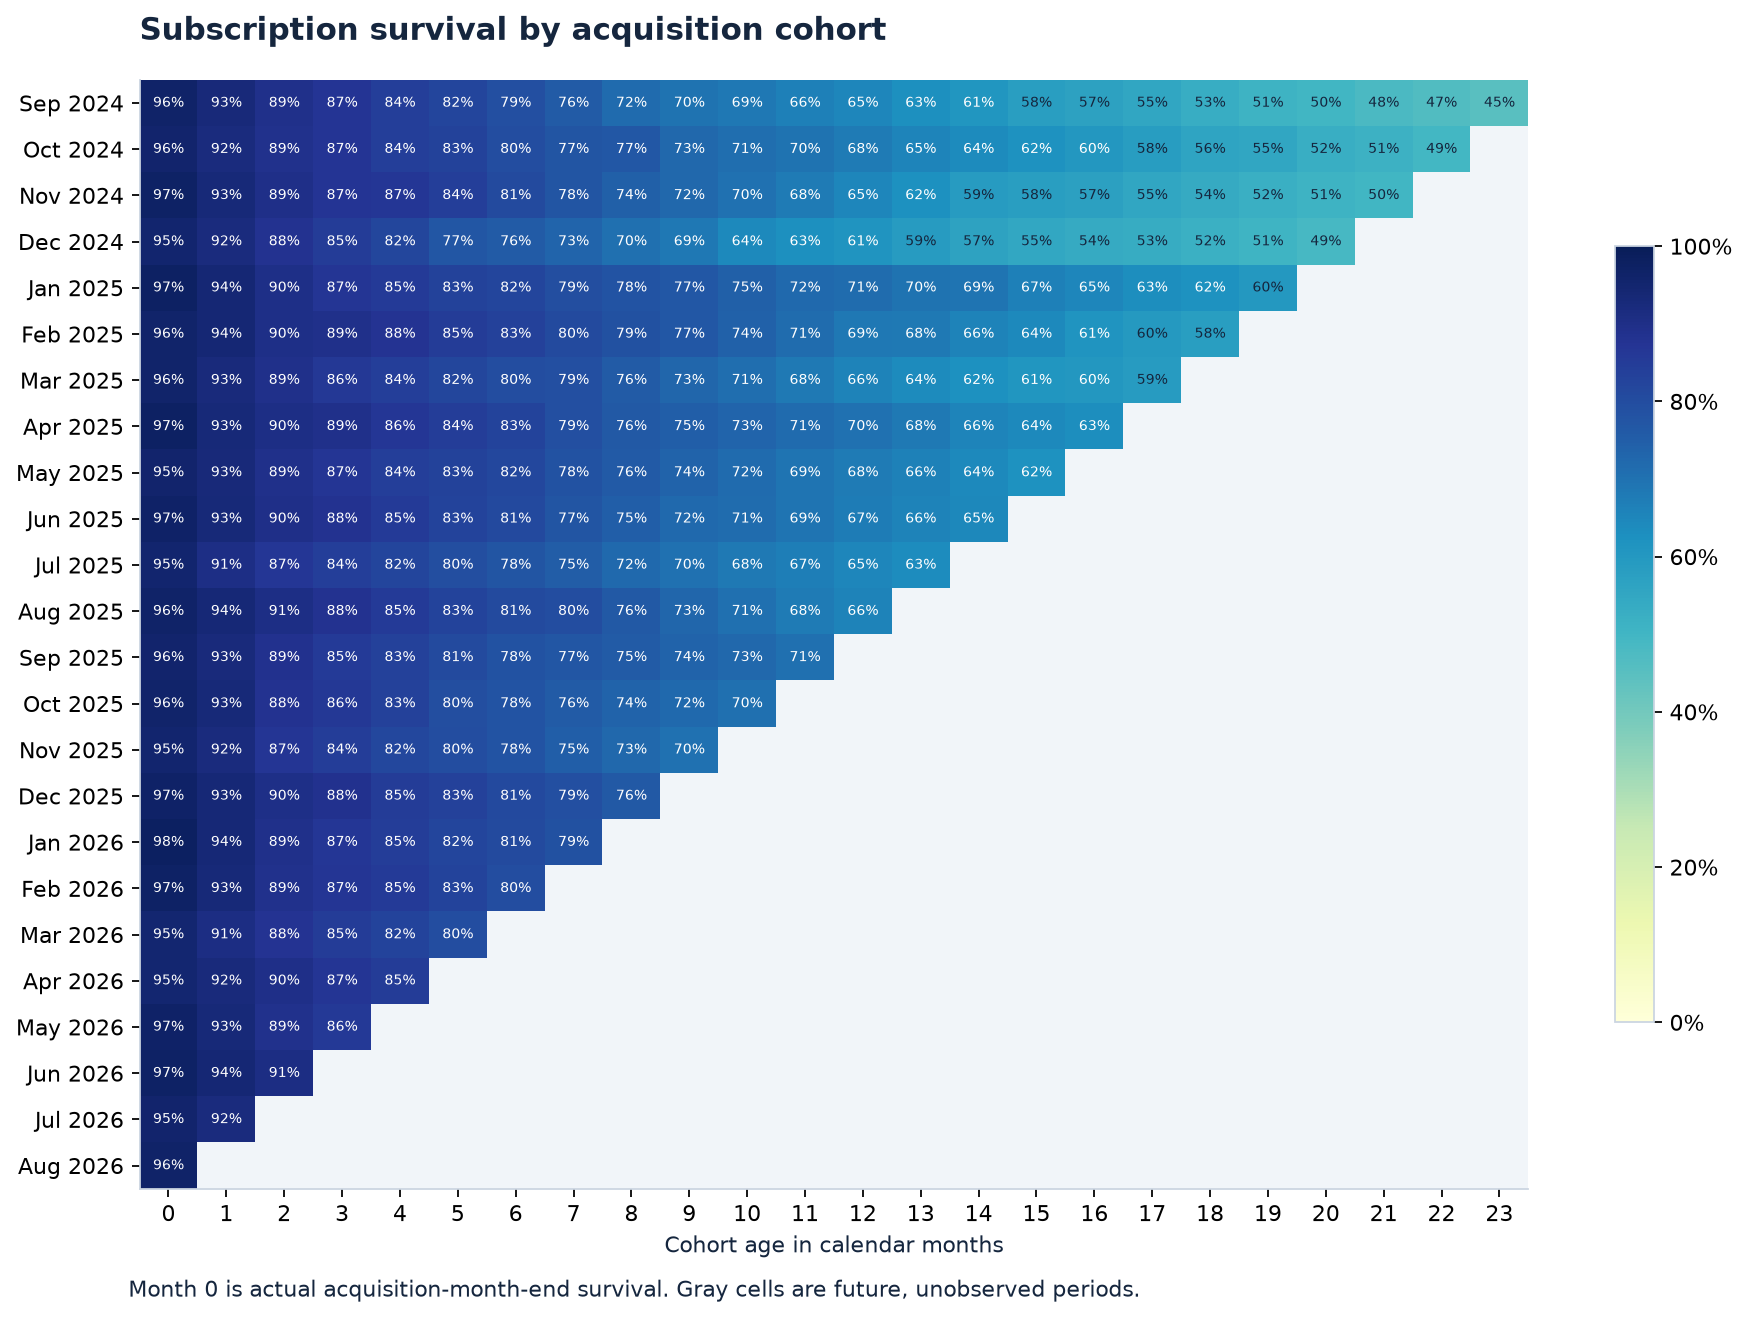

,dimension,category,eligible_customers,retained_customers,retention_rate
0,plan_type,Basic,3368,2704,0.802850
1,plan_type,Premium,1740,1399,0.804023
2,plan_type,Standard,3123,2478,0.793468
3,contract_type,Annual,2271,1957,0.861735
4,contract_type,Monthly,5960,4624,0.775839
5,acquisition_channel,Organic,2346,1882,0.802217
6,acquisition_channel,Paid Search,2196,1742,0.793260
7,acquisition_channel,Partner,806,642,0.796526
8,acquisition_channel,Referral,1491,1246,0.835681
9,acquisition_channel,Social,1392,1069,0.767960


In [5]:
display(Image(filename=str(ROOT/'outputs/charts/cohort_retention_heatmap.png')))
display(read_csv('retention_by_dimension'))

## Verify with independently executed SQL

The SQL cohort query derives survival from customer start/end dates. The Python validation also reconciles survival against monthly snapshot activity.

In [6]:
import sqlite3
with sqlite3.connect(ROOT/'outputs/churn_retention.sqlite') as conn:
    display(pd.read_sql_query('SELECT snapshot_month,SUM(start_mrr) AS opening_mrr,SUM(new_mrr) AS new_mrr,SUM(churned_mrr) AS churned_mrr,SUM(end_mrr) AS closing_mrr FROM monthly_snapshots GROUP BY snapshot_month ORDER BY snapshot_month DESC LIMIT 6',conn))

,snapshot_month,opening_mrr,new_mrr,churned_mrr,closing_mrr
0,2026-08-01,437436.25,35969.80,15176.45,458229.60
1,2026-07-01,415788.85,34288.30,12640.90,437436.25
2,2026-06-01,395040.50,33440.15,12691.80,415788.85
3,2026-05-01,375092.30,30429.45,10481.25,395040.50
4,2026-04-01,359574.30,28568.85,13050.85,375092.30
5,2026-03-01,341409.30,30180.70,12015.70,359574.30
